In [1]:
!pip install scipy

  Using cached scipy-1.16.3-cp312-cp312-win_amd64.whl.metadata (60 kB)
Using cached scipy-1.16.3-cp312-cp312-win_amd64.whl (38.6 MB)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency 
import kagglehub 
import os 

def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    
    # Número total de observaciones (n)
    n = confusion_matrix.sum().sum()
    
    # Obtenemos el número de filas (r) y columnas (k)
    r, k = confusion_matrix.shape
    
    # Aplicamos la fórmula de Cramér's V
    # V = sqrt( chi2 / (n * (min(k,r) - 1)) )
    # Usamos np.sqrt para calcular la raíz cuadrada
    v = np.sqrt(chi2 / (n * (min(k,r) - 1)))
    
    return v

print("Librerías y función 'cramers_v' definidas con éxito.")

# Descarga del dataset:
try:
    path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
    print("\nPath to dataset files:", path)
    
    # Encontrar y cargar el archivo CSV
    file_name = [f for f in os.listdir(path) if f.endswith('.csv')][0]
    full_path = os.path.join(path, file_name)
    
    df = pd.read_csv(full_path)
    print("\nDataset cargado con éxito. ¡Estamos listos para empezar la Parte 1!")
    print(df.head())
    print(df.info())

except Exception as e:
    print(f"\nOcurrió un error en la carga del dataset: {e}")
    print("Asegúrate de que 'kagglehub' esté configurado correctamente.")

c:\Users\cmoan\miniforge3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Librerías y función 'cramers_v' definidas con éxito.

Path to dataset files: C:\Users\cmoan\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3

Dataset cargado con éxito. ¡Estamos listos para empezar la Parte 1!
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  

# Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


In [6]:
!pip install jinja2

In [7]:
# 1. Create the contingency table
crosstab_df = pd.crosstab(df['category'], df['isBestSeller'])

# 2. Calculate the proportion of best-sellers (True) for each category
# We use normalize='index' to get proportions per row (category)
proportion_df = pd.crosstab(df['category'], df['isBestSeller'], normalize='index') * 100

# 3. Sort by the proportion of 'True' (Best Seller)
proportion_df_sorted = proportion_df.sort_values(by=True, ascending=False)

# Display the result of the top 10 categories with the highest proportion of Best-Sellers
print("## Top 10 Categories with the Highest Proportion of Best Sellers:\n")
print(proportion_df_sorted.head(10))


## Top 10 Categories with the Highest Proportion of Best Sellers:

isBestSeller                        False     True 
category                                           
Grocery                         94.186533  5.813467
Smart Home Security & Lighting  94.230769  5.769231
Health & Personal Care          94.231372  5.768628
Mobile Phone Accessories        95.752896  4.247104
Power & Hand Tools              96.466105  3.533895
Billiard, Snooker & Pool        96.787149  3.212851
Pet Supplies                    96.979972  3.020028
Home Brewing & Wine Making      97.154472  2.845528
Mirrors                         97.200000  2.800000
Wind Instruments                97.200000  2.800000


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [23]:
from scipy.stats import chi2_contingency 

# Paso 1: Obtener la tabla de CONTEOS de frecuencias (no proporciones)
crosstab_df_counts = pd.crosstab(df['category'], df['isBestSeller'])

# A. Chi-square Test
# El test devuelve: (chi2_statistic, p_value, degrees_of_freedom, expected_frequencies)
# Almacenamos los resultados en variables para poder interpretarlos.
chi2, p_value, dof, expected = chi2_contingency(crosstab_df_counts)

print(f"## Chi-square Test (Categoría vs Best Seller)")
print(f"Estadístico Chi-cuadrado: {chi2:.2f}")
print(f"Valor p (p-value): {p_value}")

# B. Cramér's V (usando la función que definimos)
# Aquí llamamos a la función 'cramers_v' que debe estar definida
v_cramer = cramers_v(crosstab_df_counts)
print(f"V de Cramér: {v_cramer:.4f}")

# --- Interpretación ---
alpha = 0.05
print("\nConclusión sobre la Independencia:")
if p_value < alpha:
    print(f"Como el valor p ({p_value}) es menor que el nivel de significancia ({alpha}), rechazamos la Hipótesis Nula (H₀).")
    print("Conclusión: Existe una relación estadísticamente significativa entre la categoría del producto y el estatus de Best Seller.")
else:
    print(f"Como el valor p ({p_value}) es mayor que el nivel de significancia ({alpha}), NO rechazamos la Hipótesis Nula (H₀).")
    print("Conclusión: No hay evidencia suficiente de una relación estadísticamente significativa.")

## Chi-square Test (Categoría vs Best Seller)
Estadístico Chi-cuadrado: 36540.20
Valor p (p-value): 0.0
V de Cramér: 0.1223

Conclusión sobre la Independencia:
Como el valor p (0.0) es menor que el nivel de significancia (0.05), rechazamos la Hipótesis Nula (H₀).
Conclusión: Existe una relación estadísticamente significativa entre la categoría del producto y el estatus de Best Seller.


3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

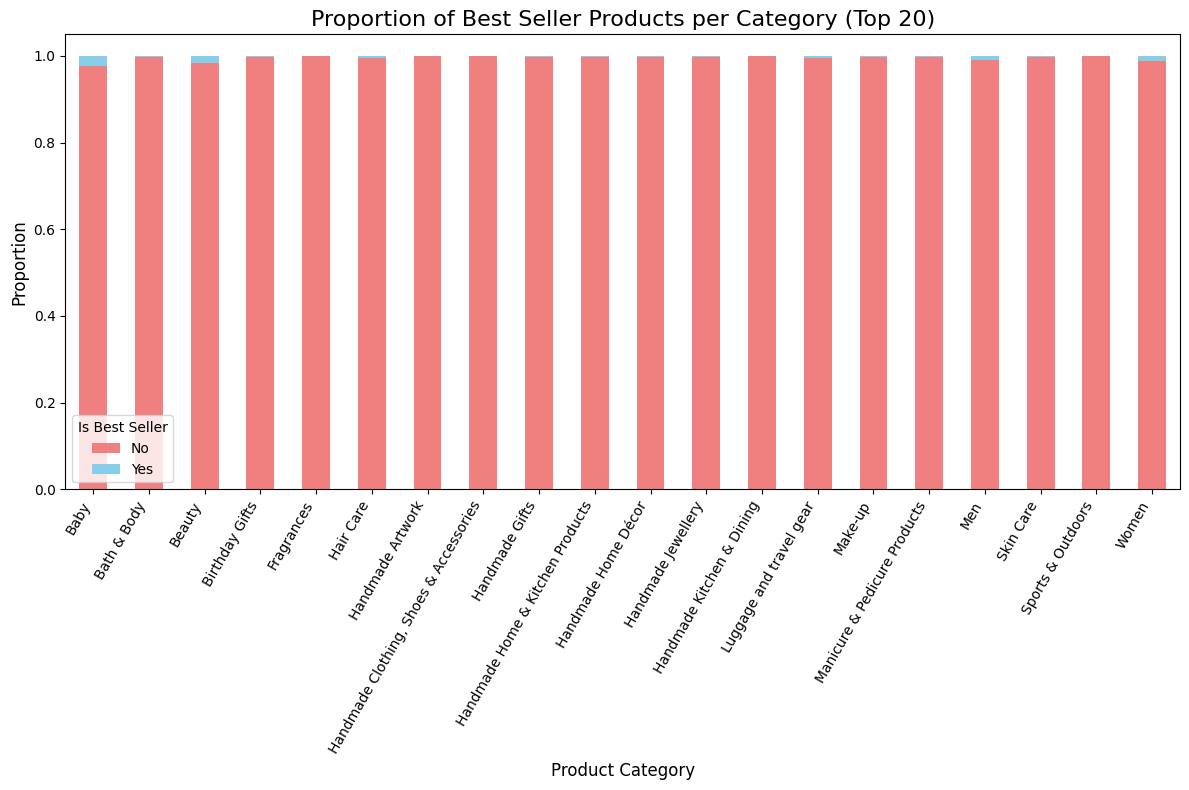

Visualization of Category vs Best Seller relationship is ready.


In [9]:
# 1. Get the Top 20 categories based on product count
top_20_categories = df['category'].value_counts().nlargest(20).index

# 2. Filter the DataFrame to only include the Top 20
df_top_20 = df[df['category'].isin(top_20_categories)]

# 3. Create the contingency table for the plot, normalized by index to show proportions
crosstab_plot = pd.crosstab(df_top_20['category'], df_top_20['isBestSeller'], normalize='index')

# Create the figure and axes
plt.figure(figsize=(12, 8))

# Plot the stacked bar chart. We use .plot() on the crosstab object.
# The 'False' (Non-Best Seller) proportion should be the largest part of the bar.
# 'gca()' stands for 'Get Current Axes'
crosstab_plot.plot(kind='bar', stacked=True, color=['lightcoral', 'skyblue'], ax=plt.gca()) 

plt.title('Proportion of Best Seller Products per Category (Top 20)', fontsize=16)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Proportion', fontsize=12)
plt.legend(title='Is Best Seller', labels=['No', 'Yes'])
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

print("Visualization of Category vs Best Seller relationship is ready.")

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [11]:
# Calculate Q1, Q3, and IQR for the 'price' column
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define the outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create the clean DataFrame (df_clean) by filtering out outliers
df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)].copy()

# Print the results
print("## Outlier Removal using IQR on Price")
print(f"Q1 (25th percentile): {Q1:.2f}")
print(f"Q3 (75th percentile): {Q3:.2f}")
print(f"IQR (Interquartile Range): {IQR:.2f}")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")
print(f"Original DataFrame size: {len(df)} rows")
print(f"Cleaned DataFrame size: {len(df_clean)} rows")
print(f"Number of rows removed (outliers): {len(df) - len(df_clean)} rows")

## Outlier Removal using IQR on Price
Q1 (25th percentile): 9.99
Q3 (75th percentile): 45.99
IQR (Interquartile Range): 36.00
Lower Bound: -44.01
Upper Bound: 99.99
Original DataFrame size: 2443651 rows
Cleaned DataFrame size: 2115963 rows
Number of rows removed (outliers): 327688 rows


In [13]:
# 1. Calculate the median price for each category in the clean DataFrame
median_prices = df_clean.groupby('category')['price'].median()

# 2. Sort to find the highest median price
highest_median_category = median_prices.sort_values(ascending=False).head(1)

print("## Category with the Highest Median Price (Analytical Result):")
print(highest_median_category)

## Category with the Highest Median Price (Analytical Result):
category
Desktop PCs    74.0
Name: price, dtype: float64


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

C:\Users\cmoan\AppData\Local\Temp\ipykernel_22772\346801609.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='category', y='price', data=df_violin, order=top_20_categories_clean, palette='pastel')


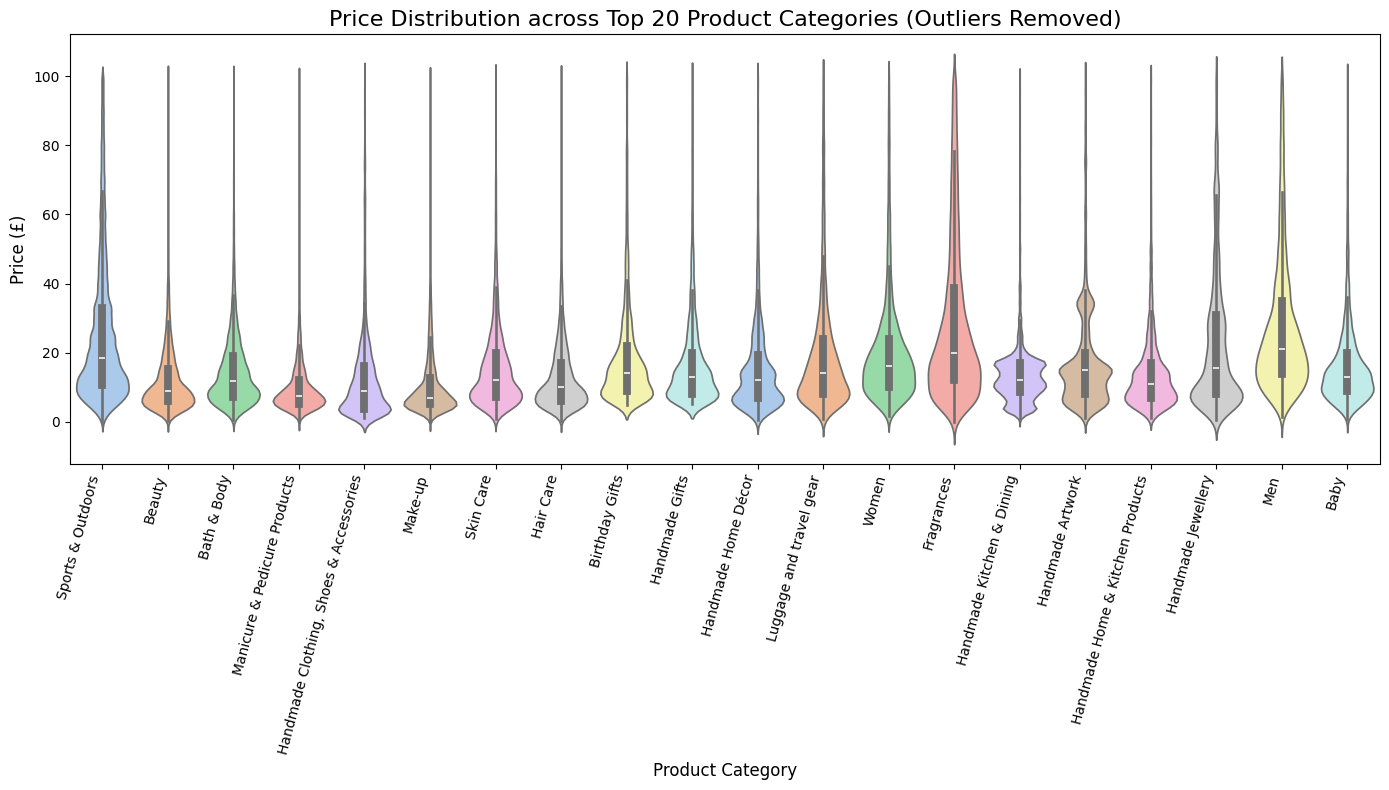

Violin plot visualization is ready.


In [14]:
# 1. Get the Top 20 categories based on the count in the clean DataFrame
top_20_categories_clean = df_clean['category'].value_counts().nlargest(20).index

# 2. Filter the clean DataFrame for the top 20 categories
df_violin = df_clean[df_clean['category'].isin(top_20_categories_clean)]

# 3. Create the Violin Plot
plt.figure(figsize=(14, 8))
# Set the 'order' parameter to ensure the categories are plotted correctly
sns.violinplot(x='category', y='price', data=df_violin, order=top_20_categories_clean, palette='pastel')

plt.title('Price Distribution across Top 20 Product Categories (Outliers Removed)', fontsize=16)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Price (£)', fontsize=12)
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

print("Violin plot visualization is ready.")

Análisis del Violin Plot
Al observar el gráfico, podemos notar:

-Forma de la Distribución: La mayoría de las categorías muestran una distribución de precios fuertemente sesgada a la derecha (concentrada en precios bajos), lo cual es típico en el comercio electrónico.

-Variabilidad (Ancho): Algunas categorías tienen una variabilidad de precios mayor (violines más anchos en la base) que otras.

-Mediana (Punto Blanco): El punto blanco (mediana) en la mayoría de las categorías se encuentra en la parte inferior del eje Y, confirmando que la mayoría de los productos son de bajo precio (debajo de $\text{£}20$).

In [16]:
# 1. Calculate the mean (average) price for each category in the clean DataFrame
mean_prices = df_clean.groupby('category')['price'].mean()

# 2. Sort to find the highest average price
highest_mean_category = mean_prices.sort_values(ascending=False).head(1)

print("## Category with the Highest Average Price (Analytical Result):")
print(highest_mean_category)

## Category with the Highest Average Price (Analytical Result):
category
Motherboards    68.772432
Name: price, dtype: float64


2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

C:\Users\cmoan\AppData\Local\Temp\ipykernel_22772\2607644278.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='category', y='price', data=df_bar, order=top_10_categories_clean, palette='viridis')


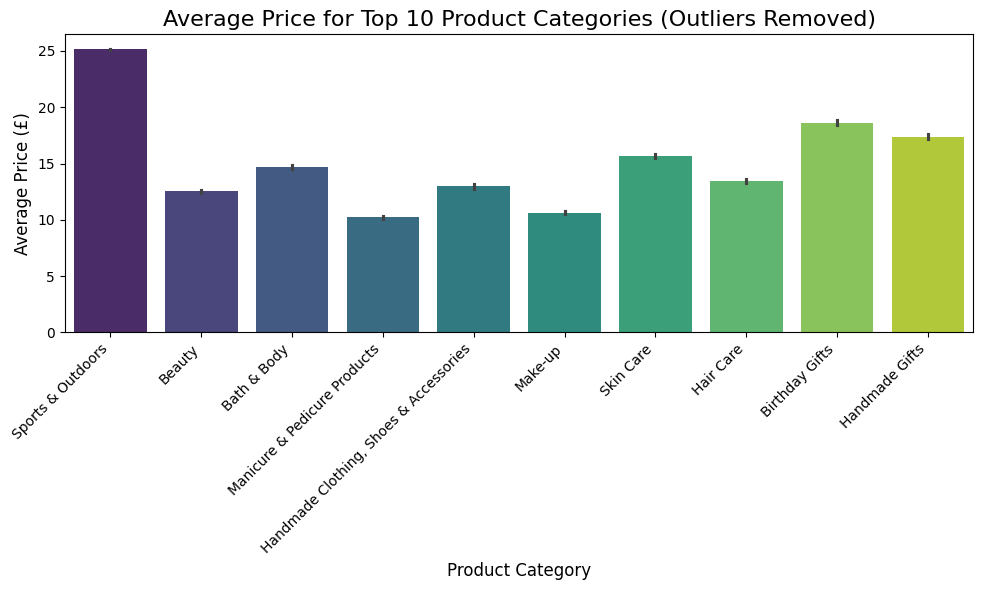

Bar chart visualization of Average Prices is ready.


In [17]:
# 1. Get the Top 10 categories based on the count in the clean DataFrame
top_10_categories_clean = df_clean['category'].value_counts().nlargest(10).index

# 2. Filter the clean DataFrame for the top 10 categories
df_bar = df_clean[df_clean['category'].isin(top_10_categories_clean)]

# 3. Create the Bar Chart
plt.figure(figsize=(10, 6))
# Use seaborn barplot. The default estimator is the mean (average).
sns.barplot(x='category', y='price', data=df_bar, order=top_10_categories_clean, palette='viridis')

plt.title('Average Price for Top 10 Product Categories (Outliers Removed)', fontsize=16)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Average Price (£)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Bar chart visualization of Average Prices is ready.")

In [18]:
# 1. Calculate the median 'stars' (rating) for each category in the clean DataFrame
median_ratings = df_clean.groupby('category')['stars'].median()

# 2. Sort to find the highest median rating
highest_median_rating_category = median_ratings.sort_values(ascending=False).head(1)

print("## Category with the Highest Median Rating (Analytical Result):")
print(highest_median_rating_category)

## Category with the Highest Median Rating (Analytical Result):
category
Computer Memory    4.7
Name: stars, dtype: float64


3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

C:\Users\cmoan\AppData\Local\Temp\ipykernel_22772\658533034.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='stars', data=df_box, order=top_10_categories_clean, palette='Set3')


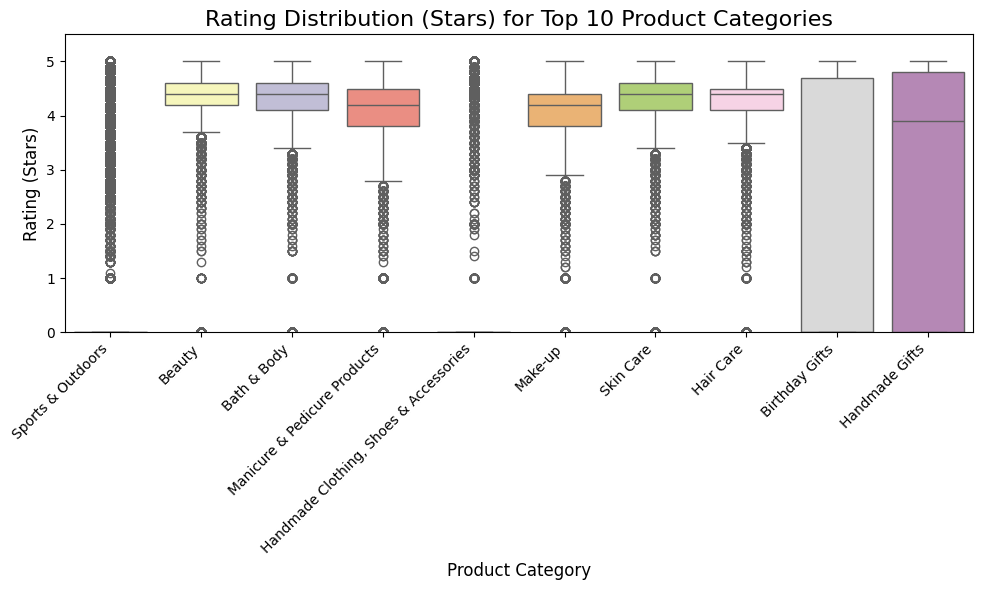

Box plot visualization of Rating Distribution is ready.


In [19]:
# 1. Get the Top 10 categories based on the count in the clean DataFrame (same as in Bar Chart step)
top_10_categories_clean = df_clean['category'].value_counts().nlargest(10).index

# 2. Filter the clean DataFrame for the top 10 categories
df_box = df_clean[df_clean['category'].isin(top_10_categories_clean)]

# 3. Create the Box Plot
plt.figure(figsize=(10, 6))
# Use seaborn boxplot to visualize rating distribution
sns.boxplot(x='category', y='stars', data=df_box, order=top_10_categories_clean, palette='Set3')

plt.title('Rating Distribution (Stars) for Top 10 Product Categories', fontsize=16)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Rating (Stars)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 5.5) # Set Y-limit to show the full 5-star range clearly
plt.tight_layout()
plt.show()

print("Box plot visualization of Rating Distribution is ready.")

Análisis del Box Plot Al revisar el gráfico que has generado, podemos observar:

Altas Medianas: La mayoría de las categorías principales (la línea dentro de la caja) tienen una mediana de valoración (rating) muy alta, oscilando entre 4 y 5 estrellas.

Baja Variabilidad: Las cajas son relativamente estrechas en la parte superior del gráfico, lo que sugiere que el $50\%$ central de las valoraciones (el IQR) está muy concentrado entre $4.0$ y $5.0$ estrellas. Esto indica que la calidad percibida es consistentemente alta en las categorías más comunes.

Outliers: Hay una cantidad significativa de puntos circulares (outliers) que se extienden hasta la valoración mínima de 1 estrella. Esto representa productos que recibieron valoraciones muy bajas, a pesar de la alta valoración general de la categoría.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

### Part 3: Investigating the Interplay Between Product Prices and Ratings
**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	

In [21]:
# Calculate the Pearson correlation coefficient between 'price' and 'stars'
correlation_coefficient = df_clean['price'].corr(df_clean['stars'])

print("## Correlation Analysis (Price vs Stars)")
print(f"Pearson Correlation Coefficient (r): {correlation_coefficient:.4f}")

# Interpretation based on common correlation guidelines:
if abs(correlation_coefficient) < 0.1:
    strength = "Very Weak/Negligible"
elif abs(correlation_coefficient) < 0.3:
    strength = "Weak"
elif abs(correlation_coefficient) < 0.5:
    strength = "Moderate"
else:
    strength = "Strong"

print(f"Interpretation: There is a {strength} correlation between price and product rating (stars).")

## Correlation Analysis (Price vs Stars)
Pearson Correlation Coefficient (r): -0.0777
Interpretation: There is a Very Weak/Negligible correlation between price and product rating (stars).


2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

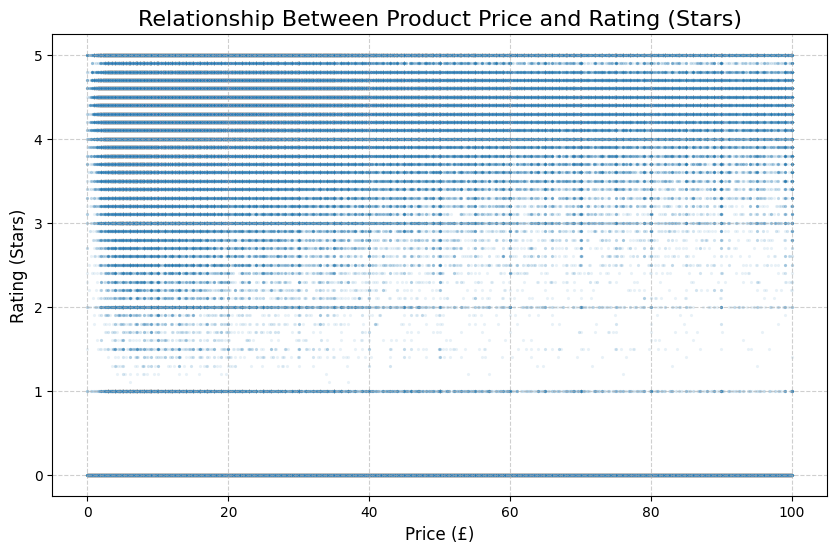

Scatter plot visualization of Price vs. Stars is ready.


In [22]:
# Create a Scatter Plot to visualize the relationship between price and stars
plt.figure(figsize=(10, 6))

# Use 'alpha' to handle overplotting by making points slightly transparent
# Use 's=5' to make the marker size smaller for better density visualization
sns.scatterplot(x='price', y='stars', data=df_clean, alpha=0.1, s=5)

plt.title('Relationship Between Product Price and Rating (Stars)', fontsize=16)
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Rating (Stars)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("Scatter plot visualization of Price vs. Stars is ready.")

# Conclusiones Finales del Laboratorio

I. Best Seller Status vs. CategoryDominancia de No Best Sellers: El dataset está fuertemente sesgado, con más del $94\%$ de los productos clasificados como isBestSeller = False.

    - Relación Estadística: El test Chi-cuadrado confirmó que existe una relación estadísticamente significativa entre la categoría y el estatus de Best Seller ($p \approx 0.0$).
    
    - Fuerza de la Asociación: La V de Cramér ($0.1223$) indicó que esta relación es débil, lo que significa que la categoría por sí sola no es un gran predictor del estatus de Best Seller.

II. Distribución de Precios y Ratings
    - Limpieza de Datos: Se eliminaron $327,688$ outliers de precio (productos $\ge \text{£}100.00$), creando un conjunto de datos más robusto (df_clean).

    - Mediana vs. Media de Precios:La mediana de precios más alta fue para Desktop PCs ($\text{£}74.00$).

    - La media de precios más alta (entre todas las categorías) fue para Motherboards ($\text{£}68.77$).
    
    - Ratings Altos: La categoría con la mediana de valoración más alta fue Computer Memory ($4.7$ estrellas), y la mayoría de las Top 10 categorías muestran una valoración media muy alta (cercana a $4.5$ o $5.0$).

III. Precio vs. RatingCorrelación Negligible: 

    - La correlación de Pearson ($r = -0.0777$) demostró una relación lineal muy débil y negativa entre el precio y la valoración (estrellas).

    - Implicación: Esto sugiere que, para los productos con un precio inferior a $\text{£}100.00$, el precio no es un indicador confiable de la satisfacción del cliente (rating).